# GLoRIA on CheXpert dataset

In [1]:
# Imports & environment configurations
import importlib.util
import json
import subprocess
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageOps
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    precision_recall_curve,
    precision_recall_fscore_support,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GroupShuffleSplit
from torch import nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
from torchvision import transforms

SEED = 42
EPOCHS = 50
PATIENCE = 10
IMAGE_BATCH_SIZE = 64
HEAD_BATCH_SIZE = 64
LABELS = ['Atelectasis', 'Cardiomegaly', 'Consolidation', 'Edema', 'Pleural Effusion']
UNCERTAIN = {'Atelectasis': 1, 'Cardiomegaly': 0, 'Consolidation': 0,
             'Edema': 1, 'Pleural Effusion': 1}

INPUT = Path('/kaggle/input')
WORK = Path('/kaggle/working')
RESULTS = WORK / 'gloria_chexpert_results'
RESULTS.mkdir(parents=True, exist_ok=True)
run_start = time.perf_counter()

if not torch.cuda.is_available() or torch.cuda.device_count() != 2:
    raise RuntimeError('Select GPU T4 x2 in Kaggle Notebook settings.')
torch.manual_seed(SEED)
np.random.seed(SEED)
print('Using:', torch.cuda.get_device_name(0), 'and', torch.cuda.get_device_name(1))


Using: Tesla T4 and Tesla T4


In [2]:
# Fetch CheXpert data, download GLoRIA model weights, and clone the official repository
data_roots = [
    path.parent for path in INPUT.rglob('train.csv')
    if (path.parent / 'valid.csv').is_file()
    and (path.parent / 'train').is_dir()
    and (path.parent / 'valid').is_dir()
]
checkpoints = list(INPUT.rglob('chexpert_resnet50.ckpt'))
if len(data_roots) != 1:
    raise FileNotFoundError('Attach one CheXpert-v1.0-small Kaggle dataset with train.csv and valid.csv.')
if len(checkpoints) != 1:
    raise FileNotFoundError('Attach the official chexpert_resnet50.ckpt as a Kaggle input.')

data_root = data_roots[0]
checkpoint_path = checkpoints[0]
repo = WORK / 'gloria_official'
if not (repo / 'gloria/models/cnn_backbones.py').is_file():
    subprocess.run(
        ['git', 'clone', '--depth', '1', 'https://github.com/marshuang80/gloria.git', str(repo)],
        check=True,
    )
print('CheXpert:', data_root)
print('GLoRIA checkpoint:', checkpoint_path)


Cloning into '/kaggle/working/gloria_official'...


CheXpert: /kaggle/input/datasets/ashery/chexpert
GLoRIA checkpoint: /kaggle/input/datasets/shadril238/gloria-chexpert-checkpoint/chexpert_resnet50.ckpt


In [3]:
# Keep frontal images, apply GLoRIA's label policy, and split training data for validation
def clean_labels(frame, expert_test=False):
    frame = frame.loc[frame['Frontal/Lateral'] == 'Frontal'].copy()
    frame['patient_id'] = frame['Path'].str.extract(r'(patient\d+)')
    if frame['patient_id'].isna().any():
        raise ValueError('CheXpert paths must contain patient IDs.')
    for label in LABELS:
        values = pd.to_numeric(frame[label], errors='coerce')
        if expert_test:
            if not values.isin([0, 1]).all():
                raise ValueError(f'Expert test labels for {label} must be 0 or 1.')
        else:
            values = values.fillna(0).replace(-1, UNCERTAIN[label])
        frame[label] = values.astype('float32')
    return frame.reset_index(drop=True)

all_train = clean_labels(pd.read_csv(data_root / 'train.csv'))
test_df = clean_labels(pd.read_csv(data_root / 'valid.csv'), expert_test=True)

split = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=SEED)
train_rows, val_rows = next(split.split(all_train, groups=all_train['patient_id']))
train_df = all_train.iloc[train_rows].reset_index(drop=True)
val_df = all_train.iloc[val_rows].reset_index(drop=True)

for name, frame in [('Train', train_df), ('Validation', val_df), ('Test', test_df)]:
    print(f'{name}: {len(frame):,} images from {frame.patient_id.nunique():,} patients')


Train: 171,927 images from 58,080 patients
Validation: 19,100 images from 6,454 patients
Test: 202 images from 200 patients


In [4]:
# Resolve image paths and build the same 256-to-224 normalized image input for every split
def image_path(raw_path):
    parts = Path(raw_path).parts
    folder = 'train' if 'train' in parts else 'valid'
    return data_root.joinpath(*parts[parts.index(folder):])

for frame in (train_df, val_df, test_df):
    frame['image_path'] = frame['Path'].map(image_path)

transform = transforms.Compose([
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

class CheXpertImages(Dataset):
    def __init__(self, frame):
        self.paths = frame['image_path'].tolist()

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image:
            image = ImageOps.pad(
                image.convert('L'), (256, 256),
                method=Image.Resampling.BILINEAR, color=0
            ).convert('RGB')
            return transform(image)

def image_loader(frame):
    return DataLoader(
        CheXpertImages(frame), batch_size=IMAGE_BATCH_SIZE,
        shuffle=False, num_workers=4, pin_memory=True
    )

print('Image preparation ready.')


Image preparation ready.


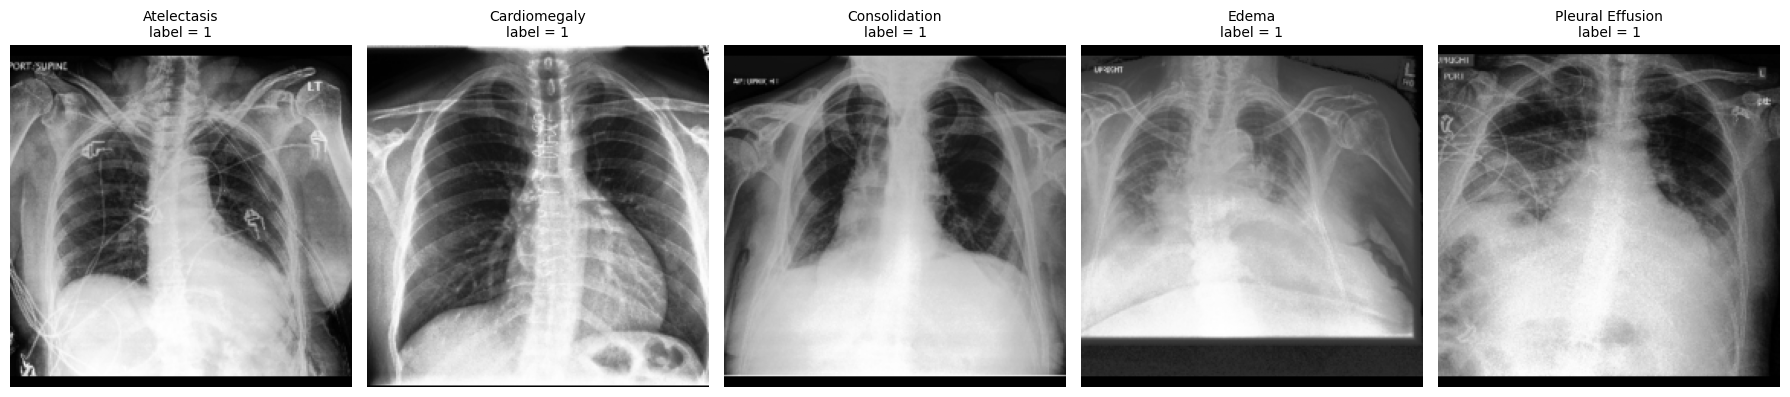

In [5]:
# Show one positive training image for each CheXpert finding.
sample_rows = []

for index, label in enumerate(LABELS):
    row = train_df.loc[train_df[label] == 1].sample(
        n=1, random_state=SEED + index
    ).iloc[0]
    sample_rows.append(row)

sample_images = CheXpertImages(pd.DataFrame(sample_rows).reset_index(drop=True))
fig, axes = plt.subplots(1, len(LABELS), figsize=(18, 4))

for index, (ax, label) in enumerate(zip(axes, LABELS)):
    image = sample_images[index][0].numpy() * 0.5 + 0.5
    ax.imshow(image, cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'{label}\nlabel = 1', fontsize=10)
    ax.axis('off')

fig.tight_layout()
fig.savefig(RESULTS / 'sample_positive_images.png', dpi=180)
plt.show()
plt.close(fig)

In [6]:
# Load the authors' pretrained ResNet-50 image encoder
source = repo / 'gloria/models/cnn_backbones.py'
spec = importlib.util.spec_from_file_location('gloria_backbones', source)
official = importlib.util.module_from_spec(spec)
spec.loader.exec_module(official)
backbone, feature_size, _ = official.resnet_50(pretrained=False)

weights_file = torch.load(checkpoint_path, map_location='cpu', weights_only=False)
checkpoint_weights = weights_file.get('state_dict', weights_file)
model_weights = backbone.state_dict()
weights = {}
for name, value in checkpoint_weights.items():
    marker = 'img_encoder.model.'
    if marker in name:
        key = name.split(marker, 1)[1]
        if key in model_weights and value.shape == model_weights[key].shape:
            weights[key] = value
if len(weights) < 250:
    raise ValueError('The attached checkpoint is not the official GLoRIA ResNet-50 checkpoint.')
backbone.load_state_dict(weights, strict=True)
del weights_file, checkpoint_weights, model_weights, weights
backbone.eval()

class GLoRIAFeatures(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, images):
        images = nn.functional.interpolate(
            images, size=(299, 299), mode='bilinear', align_corners=True
        )
        return self.model(images)

encoder = nn.DataParallel(GLoRIAFeatures(backbone), device_ids=[0, 1]).cuda().eval()
print('Loaded GLoRIA image encoder with', feature_size, 'features per image.')


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Loaded GLoRIA image encoder with 2048 features per image.


In [7]:
# Use both T4s once to turn each image into a frozen GLoRIA feature vector
def extract_features(frame):
    vectors = np.empty((len(frame), feature_size), dtype=np.float16)
    offset = 0
    with torch.inference_mode():
        for images in image_loader(frame):
            with torch.autocast('cuda', dtype=torch.float16):
                batch = encoder(images.cuda(non_blocking=True))
            count = len(batch)
            vectors[offset:offset + count] = batch.cpu().numpy().astype(np.float16)
            offset += count
    return vectors

feature_start = time.perf_counter()
train_x = extract_features(train_df)
val_x = extract_features(val_df)
test_x = extract_features(test_df)
feature_minutes = (time.perf_counter() - feature_start) / 60

train_y = train_df[LABELS].to_numpy(dtype=np.float32)
val_y = val_df[LABELS].to_numpy(dtype=np.float32)
test_y = test_df[LABELS].to_numpy(dtype=np.float32)
print(f'Feature extraction finished in {feature_minutes:.1f} minutes.')


Feature extraction finished in 10.8 minutes.


In [8]:
# Train the linear head for up to 50 epochs, stopping after 10 epochs without validation improvement.
def head_loader(features, labels, shuffle=False):
    dataset = TensorDataset(
        torch.from_numpy(features.astype(np.float32)),
        torch.from_numpy(labels),
    )
    return DataLoader(dataset, batch_size=HEAD_BATCH_SIZE, shuffle=shuffle)

train_loader = head_loader(train_x, train_y, shuffle=True)
val_loader = head_loader(val_x, val_y)

head = nn.Linear(feature_size, len(LABELS)).cuda()
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(
    head.parameters(), lr=1e-4, weight_decay=1e-6, betas=(0.5, 0.999)
)

patience = 10
epochs_without_improvement = 0
best_val_loss = float('inf')
history = []
training_start = time.perf_counter()

for epoch in range(1, EPOCHS + 1):
    head.train()
    train_loss = 0.0

    for features, labels in train_loader:
        features, labels = features.cuda(), labels.cuda()
        optimizer.zero_grad()
        loss = loss_fn(head(features), labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * len(features)

    head.eval()
    val_loss = 0.0

    with torch.inference_mode():
        for features, labels in val_loader:
            features, labels = features.cuda(), labels.cuda()
            val_loss += loss_fn(head(features), labels).item() * len(features)

    train_loss /= len(train_df)
    val_loss /= len(val_df)
    history.append({
        'epoch': epoch,
        'train_loss': train_loss,
        'val_loss': val_loss,
    })

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_without_improvement = 0
        torch.save(head.state_dict(), RESULTS / 'best_head.pt')
    else:
        epochs_without_improvement += 1

    print(
        f'Epoch {epoch:02d}/{EPOCHS} | '
        f'train loss {train_loss:.4f} | val loss {val_loss:.4f}'
    )

    if epochs_without_improvement >= patience:
        print(f'Early stopping at epoch {epoch}.')
        break

training_minutes = (time.perf_counter() - training_start) / 60
head.load_state_dict(
    torch.load(RESULTS / 'best_head.pt', map_location='cuda', weights_only=True)
)
head.eval()
print(f'Training finished')

Epoch 01/50 | train loss 0.4022 | val loss 0.3857
Epoch 02/50 | train loss 0.3863 | val loss 0.3840
Epoch 03/50 | train loss 0.3849 | val loss 0.3850
Epoch 04/50 | train loss 0.3841 | val loss 0.3826
Epoch 05/50 | train loss 0.3835 | val loss 0.3825
Epoch 06/50 | train loss 0.3830 | val loss 0.3820
Epoch 07/50 | train loss 0.3827 | val loss 0.3826
Epoch 08/50 | train loss 0.3824 | val loss 0.3818
Epoch 09/50 | train loss 0.3821 | val loss 0.3808
Epoch 10/50 | train loss 0.3819 | val loss 0.3814
Epoch 11/50 | train loss 0.3817 | val loss 0.3806
Epoch 12/50 | train loss 0.3815 | val loss 0.3805
Epoch 13/50 | train loss 0.3812 | val loss 0.3820
Epoch 14/50 | train loss 0.3811 | val loss 0.3811
Epoch 15/50 | train loss 0.3810 | val loss 0.3800
Epoch 16/50 | train loss 0.3808 | val loss 0.3799
Epoch 17/50 | train loss 0.3807 | val loss 0.3798
Epoch 18/50 | train loss 0.3806 | val loss 0.3808
Epoch 19/50 | train loss 0.3805 | val loss 0.3798
Epoch 20/50 | train loss 0.3804 | val loss 0.3807


In [9]:
# Select thresholds on validation data, then evaluate the expert test set once
def predict(features):
    results = []
    with torch.inference_mode():
        for start in range(0, len(features), 4096):
            batch = torch.from_numpy(
                features[start:start + 4096].astype(np.float32)
            ).cuda()
            results.append(head(batch).sigmoid().cpu().numpy())
    return np.concatenate(results)

val_probs = predict(val_x)
thresholds = {}
for index, label in enumerate(LABELS):
    choices = np.linspace(0.05, 0.95, 181)
    f1_scores = [
        precision_recall_fscore_support(
            val_y[:, index], val_probs[:, index] >= threshold,
            average='binary', zero_division=0
        )[2]
        for threshold in choices
    ]
    thresholds[label] = float(choices[np.argmax(f1_scores)])

test_start = time.perf_counter()
test_probs = predict(test_x)
metrics = {}
predictions = test_df[['Path', 'patient_id']].copy()
for index, label in enumerate(LABELS):
    truth = test_y[:, index].astype(int)
    probability = test_probs[:, index]
    predicted = (probability >= thresholds[label]).astype(int)
    precision, recall, f1, _ = precision_recall_fscore_support(
        truth, predicted, average='binary', zero_division=0
    )
    has_two_classes = len(np.unique(truth)) == 2
    metrics[label] = {
        'AUROC': roc_auc_score(truth, probability) if has_two_classes else float('nan'),
        'AUPRC': average_precision_score(truth, probability) if truth.sum() else float('nan'),
        'accuracy': accuracy_score(truth, predicted),
        'precision': precision, 'recall': recall, 'F1': f1,
        'threshold': thresholds[label],
    }
    predictions[f'target_{label}'] = truth
    predictions[f'probability_{label}'] = probability
    predictions[f'prediction_{label}'] = predicted

test_seconds = time.perf_counter() - test_start
print(pd.DataFrame(metrics).T.round(3).to_string())
print(f'Macro AUROC: {np.nanmean([item["AUROC"] for item in metrics.values()]):.3f}')


                  AUROC  AUPRC  accuracy  precision  recall     F1  threshold
Atelectasis       0.813  0.683     0.713      0.581   0.813  0.678      0.270
Cardiomegaly      0.837  0.765     0.752      0.944   0.258  0.405      0.255
Consolidation     0.901  0.651     0.876      0.706   0.375  0.490      0.135
Edema             0.931  0.805     0.856      0.610   0.857  0.713      0.325
Pleural Effusion  0.933  0.885     0.861      0.773   0.797  0.785      0.390
Macro AUROC: 0.883


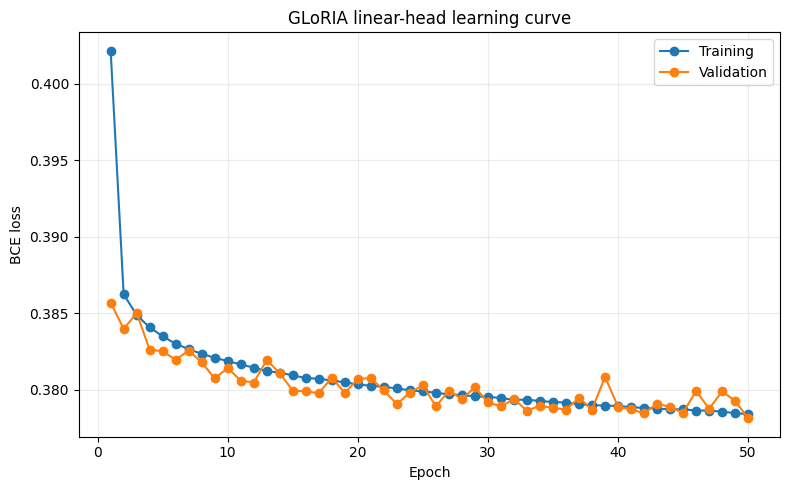

In [10]:
# Plot training and validation loss
history_df = pd.DataFrame(history)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(history_df['epoch'], history_df['train_loss'], marker='o', label='Training')
ax.plot(history_df['epoch'], history_df['val_loss'], marker='o', label='Validation')
ax.set(title='GLoRIA linear-head learning curve', xlabel='Epoch', ylabel='BCE loss')
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / 'learning_curve.png', dpi=180)
plt.show()
plt.close(fig)


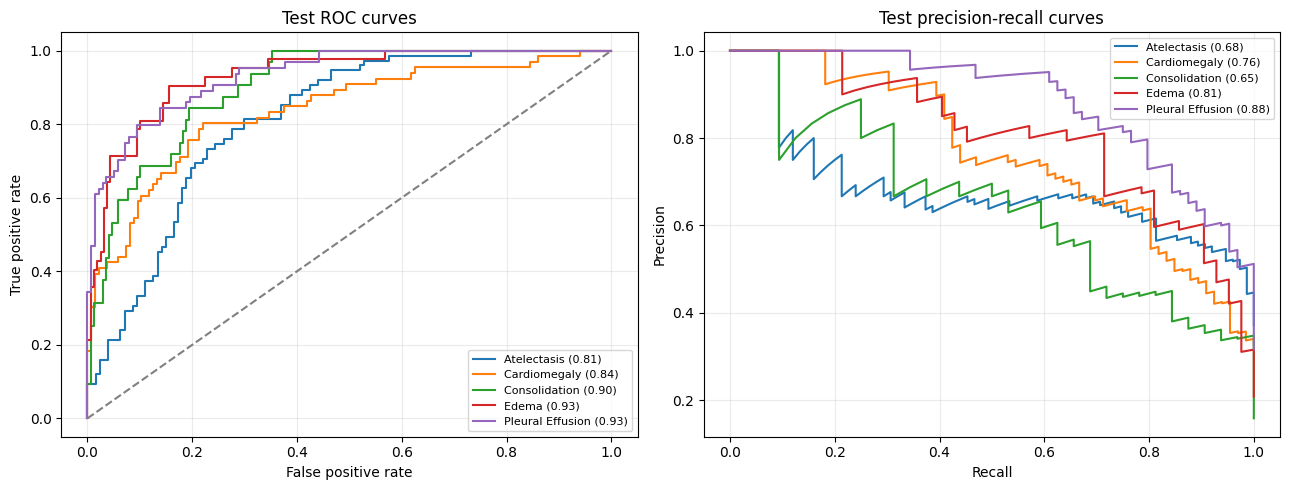

In [11]:
# Plot ROC and precision-recall curves
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for index, label in enumerate(LABELS):
    truth = test_y[:, index].astype(int)
    probability = test_probs[:, index]
    if len(np.unique(truth)) < 2:
        continue
    fpr, tpr, _ = roc_curve(truth, probability)
    precision, recall, _ = precision_recall_curve(truth, probability)
    axes[0].plot(fpr, tpr, label=f'{label} ({metrics[label]["AUROC"]:.2f})')
    axes[1].plot(recall, precision, label=f'{label} ({metrics[label]["AUPRC"]:.2f})')
axes[0].plot([0, 1], [0, 1], '--', color='gray')
axes[0].set(title='Test ROC curves', xlabel='False positive rate', ylabel='True positive rate')
axes[1].set(title='Test precision-recall curves', xlabel='Recall', ylabel='Precision')
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(RESULTS / 'test_roc_pr_curves.png', dpi=180)
plt.show()
plt.close(fig)


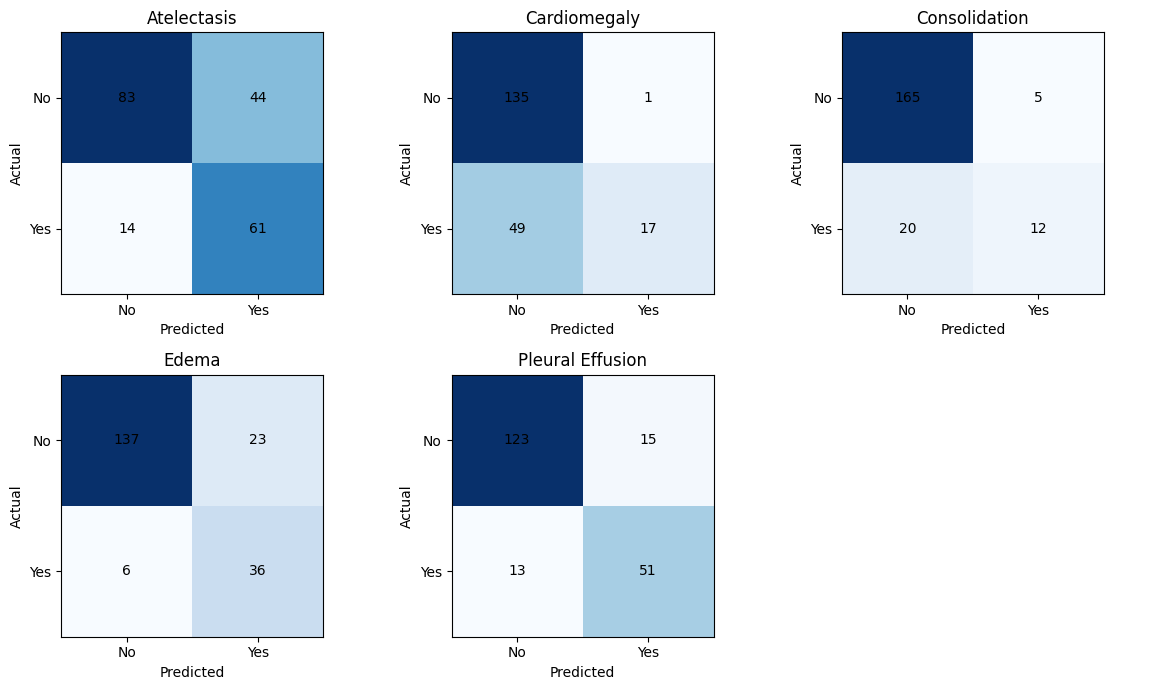

In [12]:
# Plot confusion matrix 
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for index, label in enumerate(LABELS):
    ax = axes.flat[index]
    truth = test_y[:, index].astype(int)
    predicted = (test_probs[:, index] >= thresholds[label]).astype(int)
    matrix = confusion_matrix(truth, predicted, labels=[0, 1])
    ax.imshow(matrix, cmap='Blues')
    for row in range(2):
        for col in range(2):
            ax.text(col, row, str(matrix[row, col]), ha='center', va='center')
    ax.set(
        title=label, xlabel='Predicted', ylabel='Actual',
        xticks=[0, 1], yticks=[0, 1],
        xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes']
    )
axes.flat[-1].axis('off')
fig.tight_layout()
fig.savefig(RESULTS / 'test_confusion_matrices.png', dpi=180)
plt.show()
plt.close(fig)


In [13]:
# Save results and print the measured training and total run times
history_df.to_csv(RESULTS / 'history.csv', index=False)
pd.DataFrame(metrics).T.to_csv(RESULTS / 'test_metrics.csv')
predictions.to_csv(RESULTS / 'test_predictions.csv', index=False)
for name, frame in [('train', train_df), ('validation', val_df), ('test', test_df)]:
    frame[['Path', 'patient_id', *LABELS]].to_csv(
        RESULTS / f'{name}_split.csv', index=False
    )

summary = {
    'model': 'GLoRIA frozen image encoder with linear head',
    'dataset': 'CheXpert, frontal views, five findings',
    'split': 'patient-level 90/10 train/validation; public valid.csv as test',
    'seed': SEED,
    'checkpoint': str(checkpoint_path),
    'feature_extraction_minutes': feature_minutes,
    'head_training_minutes': training_minutes,
    'test_evaluation_seconds': test_seconds,
    'total_run_minutes': (time.perf_counter() - run_start) / 60,
}
(RESULTS / 'run_info.json').write_text(json.dumps(summary, indent=2))
print(f'Feature extraction: {feature_minutes:.1f} min')
print(f'Head training:      {training_minutes:.1f} min')
print(f'Total run:          {summary["total_run_minutes"]:.1f} min')
print('Saved files to:', RESULTS)


Feature extraction: 10.8 min
Head training:      4.0 min
Total run:          43.6 min
Saved files to: /kaggle/working/gloria_chexpert_results
